# Vehicle CO2 Emissions Prediction Using Machine Learning

CS316 Phase 2, Prince Sultan University.

Fahad Albarrak (223110478), Meshal Alsuhaibani (223110309), Nawaf Alkhazy (223111223).
Supervisor: Dr. Mohammed Al Zamil.

This notebook executes the command-line pipeline. Stored outputs below come from
the bundled official NRCan 2025 snapshot. See README.md for setup and attribution.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
if not (root / 'src/analysis.py').exists():
    raise RuntimeError('Open this notebook from the project root or notebooks folder.')
sys.path.insert(0, str(root))
from src.analysis import run


## 1. Audit, fit and evaluate

Hold out complete make/model groups. Five grouped folds inside training select
the lowest mean validation MAE before calculating test predictions. This cell
regenerates the metrics, figures and train-only model artifacts.

In [2]:
summary = run(root / 'data/raw/my2025-fuel-consumption-ratings.csv', root / 'results')


Dataset: 701 records. Train/test: 564/137. Shared groups: 0.
Selected by training CV: Fuel-interaction linear regression
Mean baseline: CV MAE=52.018; test MAE=55.471; R2=-0.000012
Specifications only: CV MAE=31.173; test MAE=31.431; R2=0.663186
Fuel consumption only: CV MAE=3.146; test MAE=2.937; R2=0.992445
Phase 1 linear regression: CV MAE=3.331; test MAE=3.090; R2=0.992363
Fuel-interaction linear regression: CV MAE=1.421; test MAE=1.449; R2=0.998822


## 2. Data quality and descriptive statistics

In [3]:
audit = json.loads((root / 'results/data_audit.json').read_text())
print('Raw shape:', audit['raw_rows'], audit['raw_columns'])
print('Missing values:', sum(audit['missing_values_raw'].values()))
print('Exact duplicates removed:', audit['exact_duplicates_removed'])
print('Fuel counts:', audit['fuel_counts'])
print('Split:', audit['split'])
print()
print(pd.read_csv(root / 'results/descriptive_statistics.csv').to_string(index=False))


Raw shape: 701 15
Missing values: 0
Exact duplicates removed: 0
Fuel counts: {'Z': 385, 'X': 300, 'D': 13, 'E': 3}
Split: {'method': 'GroupShuffleSplit', 'seed': 42, 'test_fraction_of_groups': 0.2, 'train_rows': 564, 'test_rows': 137, 'train_groups': 480, 'test_groups': 120, 'overlap_groups': 0, 'group_definition': 'Make + exact stripped Model string', 'train_fuel_counts': {'Z': 309, 'X': 242, 'D': 10, 'E': 3}, 'test_fuel_counts': {'Z': 76, 'X': 58, 'D': 3, 'E': 0}}

          Unnamed: 0  count       mean       std   min   25%   50%   75%   max
     Engine size (L)  701.0   2.987304  1.179029   1.2   2.0   2.7   3.5   8.0
           Cylinders  701.0   5.410842  1.791120   3.0   4.0   4.0   6.0  16.0
 Combined (L/100 km)  701.0  10.893723  2.813618   4.4   8.8  10.8  12.6  25.0
CO2 emissions (g/km)  701.0 255.403709 65.416782 104.0 207.0 254.0 297.0 586.0


## 3. Exploratory evidence

Consumption and rated tailpipe CO2 are physically related. These are descriptive
relationships, not causal effects.

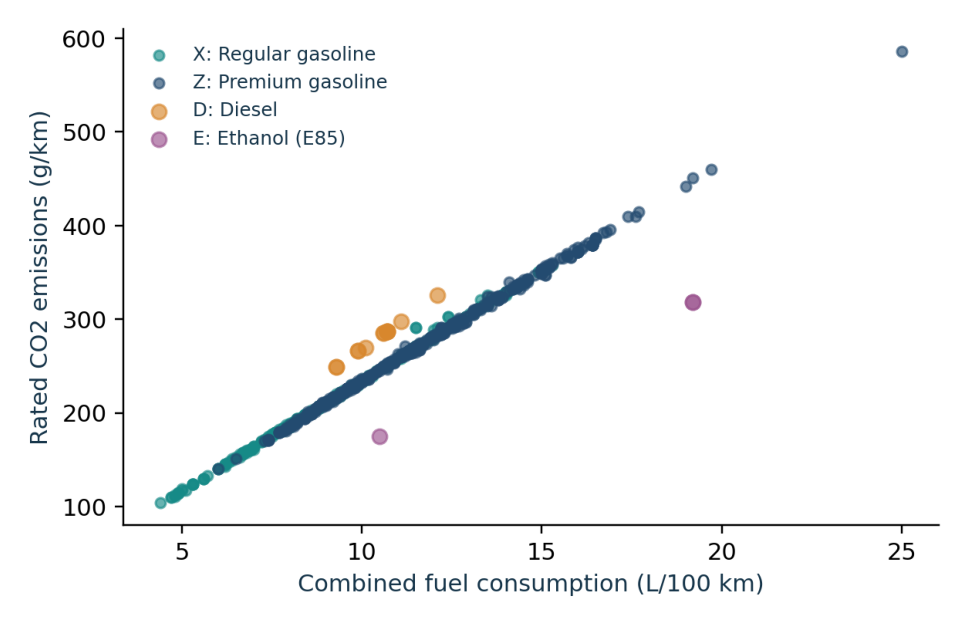

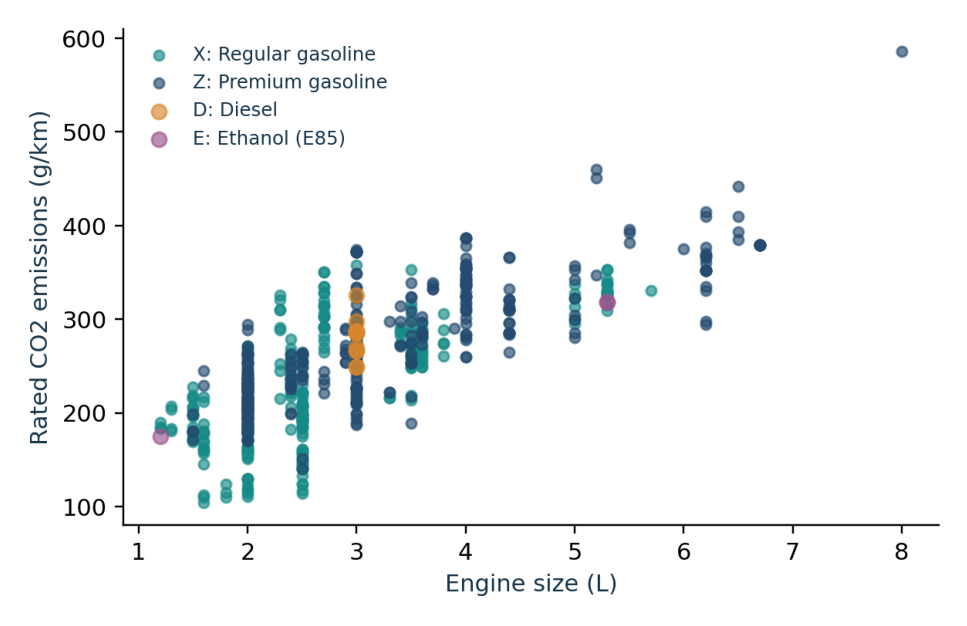

In [4]:
for filename in ['fuel_vs_co2.png', 'engine_vs_co2.png']:
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.imshow(plt.imread(root / 'results/figures' / filename))
    ax.axis('off')
    plt.show()


## 4. Model comparison

The selected model is chosen by training-only grouped CV MAE. R2 is not
classification accuracy.

In [5]:
rows = []
for m in summary['models']:
    rows.append({'model': m['name'], 'CV MAE': m['cv']['mae_mean'],
                 'test MAE': m['test']['mae'], 'test MSE': m['test']['mse'],
                 'test RMSE': m['test']['rmse'], 'test R2': m['test']['r2']})
print(pd.DataFrame(rows).to_string(index=False))
print()
print('Selected:', summary['selected_model'])
print(pd.read_csv(root / 'results/fuel_subgroup_metrics.csv').to_string(index=False))


                             model    CV MAE  test MAE    test MSE  test RMSE   test R2
                     Mean baseline 52.017633 55.470674 5278.973447  72.656544 -0.000012
               Specifications only 31.172710 31.431073 1778.011198  42.166470  0.663186
             Fuel consumption only  3.146182  2.937140   39.884803   6.315442  0.992445
         Phase 1 linear regression  3.330790  3.089758   40.314136   6.349341  0.992363
Fuel-interaction linear regression  1.420663  1.449363    6.217111   2.493414  0.998822

Selected: Fuel-interaction linear regression
fuel  count      mae      mse     rmse       r2
   D      3 0.342637 0.119684 0.345953 0.996336
   X     58 1.291010 8.528271 2.920320 0.997570
   Z     76 1.613899 4.694019 2.166569 0.999156


## 5. Held-out predictions and residuals

The holdout contains 58 regular-gasoline, 76 premium-gasoline and three diesel
records, with no E85 records. The bootstrap interval concerns aggregate test MAE
conditional on this trained model and split, not individual predictions.

95% group-bootstrap MAE interval: [1.1565996642758887, 1.8444769744514955]
Maximum absolute test error: 20.282493446316494


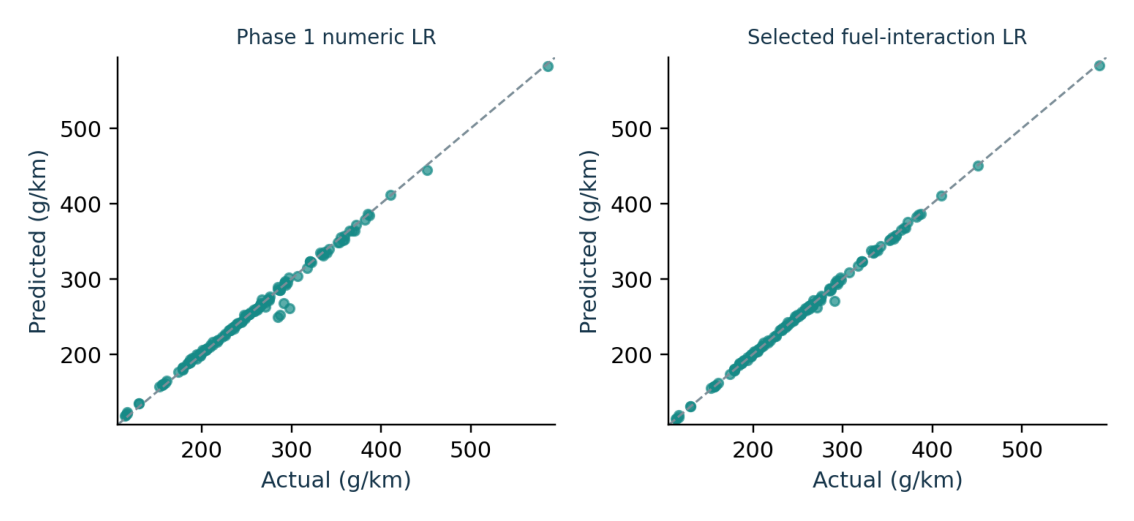

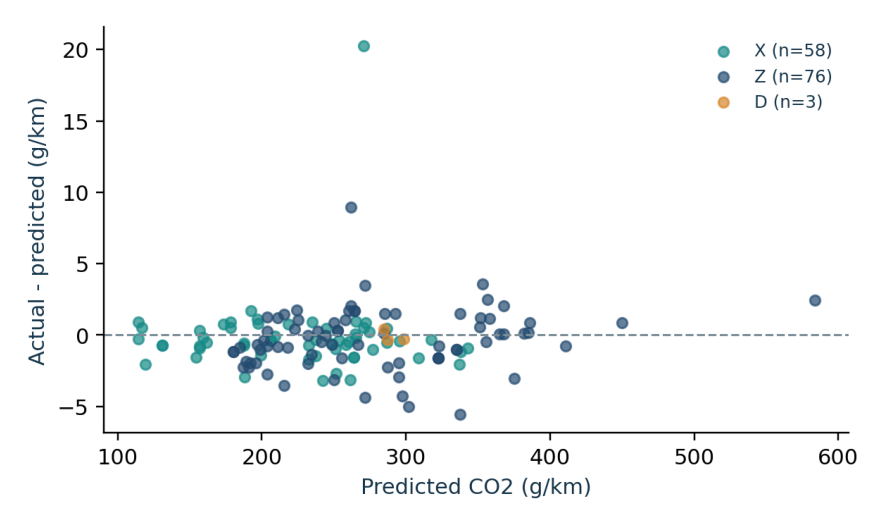

In [6]:
for filename in ['actual_vs_predicted.png', 'residuals.png']:
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.imshow(plt.imread(root / 'results/figures' / filename))
    ax.axis('off')
    plt.show()
selected = next(m for m in summary['models'] if m['name'] == summary['selected_model'])
print('95% group-bootstrap MAE interval:', selected['test_mae_cluster_bootstrap_95ci'])
print('Maximum absolute test error:', summary['selected_test_max_absolute_error'])


## 6. Memory efficiency and evidence checks

Storage is compared on the same selected columns and rows. It does not represent
peak process RAM. The tests trace targets and metrics back to source rows and
verify group separation, selection and the persisted model.

In [7]:
print(json.dumps(audit['memory'], indent=2))
import subprocess
check = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-v'],
                       cwd=root, capture_output=True, text=True)
print(check.stdout + check.stderr)
assert check.returncode == 0, 'Consistency checks failed.'


{
  "full_source_dataframe_bytes": 259266,
  "original_selected_columns_bytes": 194914,
  "selected_before_optimization_bytes": 194969,
  "selected_after_optimization_bytes": 72774,
  "selected_reduction_pct": 62.674066133590465
}
test_all_reported_test_metrics_match_predictions (test_project.ProjectEvidenceTests.test_all_reported_test_metrics_match_predictions) ... ok
test_catalog_groups_do_not_overlap (test_project.ProjectEvidenceTests.test_catalog_groups_do_not_overlap) ... ok
test_selection_uses_training_cv (test_project.ProjectEvidenceTests.test_selection_uses_training_cv) ... ok
test_serialized_model_reproduces_heldout_predictions (test_project.ProjectEvidenceTests.test_serialized_model_reproduces_heldout_predictions) ... ok
test_source_snapshot_and_audit (test_project.ProjectEvidenceTests.test_source_snapshot_and_audit) ... ok
test_transformer_handles_one_fuel_and_unseen_code (test_project.ProjectEvidenceTests.test_transformer_handles_one_fuel_and_unseen_code) ... ok

----------

## Interpretation and disclosure

The extension reduces test MAE from 3.090 to 1.449 g/km. These results estimate
published ratings from closely related fuel-consumption data. They do not validate
independent real-world, Saudi-fleet, future-year or lifecycle emissions. Different
catalog model strings may share platforms. Rare-fuel coverage is limited.

OpenAI ChatGPT assisted implementation, execution, interpretation and drafting.
Students must independently review the work and follow course policy. No official
plagiarism/similarity ratio has been measured.

The precise NRCan source URL, licence and SHA-256 hash are in data/SOURCE.md.
The report and README provide the methodological references.